In [ ]:
import matplotlib as plt
import numpy as np
from scipy.stats import weibull_min

alpha = 0.01
from scipy.stats import norm
from scipy.special import gamma
quantile = norm.isf(alpha/2.)
c = 1
sigma = np.sqrt(gamma(1 + 2./c) - gamma(1 + 1./c)**2)

X_av = X.sum() / X.size

delta = quantile * sigma / np.sqrt(X.size)
print("quantile =", quantile, " (alpha =", alpha, ")")
print("W(1, 1) mean = ", weibull_min.mean(c=1))
print("sample mean = ", X_av)
print("conf interval : (%s, %s)" % (X_av - delta, X_av + delta))

quantile = 2.575829303548901  (alpha = 0.01 )
W(1, 1) mean =  1.0
sample mean =  0.7062152673154556
conf interval : (0.23593532936993733, 1.1764952052609738)


In [13]:
sigma = np.std(X, ddof=1)
delta = quantile*sigma / np.sqrt(X.size)
print("quantile =", quantile, " (alpha =", alpha, ")")
print("W(1, 1) mean = ", weibull_min.mean(c=1))
print("sample mean = ", X_av)
print("conf interval : (%s, %s)" % (X_av - delta, X_av + delta))

quantile = 2.575829303548901  (alpha = 0.01 )
W(1, 1) mean =  1.0
sample mean =  0.7062152673154556
conf interval : (0.4421546911230458, 0.9702758435078653)


5

In [14]:
z1, z2 = weibull_min.ppf([1/3, 2/3], c=1)
print(z1, z2)

0.4054651081081643 1.0986122886681096


In [15]:
n1 = np.count_nonzero(X < z1)
n2 = np.count_nonzero((z1 <= X) & (X < z2))
n3 = np.count_nonzero(z2 <= X)
obs_freq = np.array([n1, n2, n3])
obs_freq

array([12, 10,  8])

In [16]:
exp_freq = 10
K = np.sum((obs_freq - exp_freq)**2) / exp_freq
print(K)

0.8


In [17]:
alpha=0.1
from scipy.stats import chi2
k_c = chi2.isf(alpha, df=2)
print(k_c)

4.605170185988092


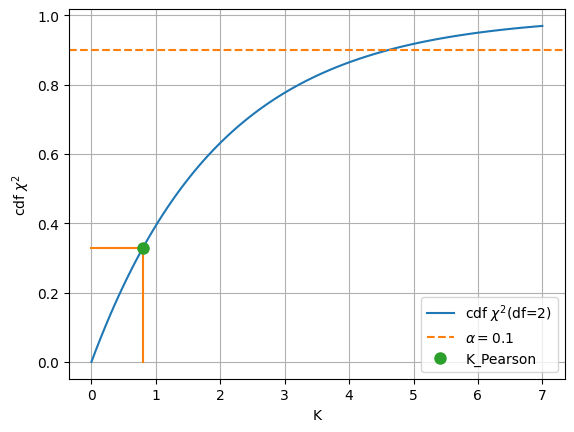

In [18]:
xx = np.linspace(0, 7, 101)
plt.plot(xx, chi2.cdf(xx, df=2),
label=r"cdf $\chi^2$(df=2)")
alpha = 0.1
plt.axhline(y=1-alpha, ls='--',
label=r"$\alpha = %s$"%alpha, color='C1')
plt.plot([K, K, 0],
[0, chi2.cdf(K, df=2), chi2.cdf(K, df=2)], '-')
plt.plot(K, chi2.cdf(K, df=2), 'o', ms=8, label='K_Pearson')
plt.legend(loc='best')
plt.xlabel('K')
plt.ylabel('cdf $\chi^2$')
plt.grid()

In [19]:
from scipy.stats import chisquare
statistic, pvalue = chisquare(obs_freq, [exp_freq]*3)
print(statistic, pvalue)

0.8 0.6703200460356394


In [20]:
chi2.sf(K, df=2) 

0.6703200460356394